In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
!nvidia-smi
!pip -q install gdown
!mkdir -p /tmp/raw
!gdown --folder https://drive.google.com/drive/folders/13dQHHW8v9gt_jIssQ5PTrJToWGUXvZey -O /tmp/raw
!ls -lh /tmp/raw
!df -h /tmp

Sun Oct 25 21:25:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!mkdir -p /kaggle/working/cricshot10k_raw
!cp /tmp/raw/*.rar /kaggle/working/cricshot10k_raw/
!ls -lh /kaggle/working/cricshot10k_raw

total 3.6G
-rw-r--r-- 1 root root 265M Oct 25 21:29 'Cover Drive.rar'
-rw-r--r-- 1 root root 206M Oct 25 21:29  Defensive.rar
-rw-r--r-- 1 root root 332M Oct 25 21:30 'Down The Wicket.rar'
-rw-r--r-- 1 root root 323M Oct 25 21:30  Flick.rar
-rw-r--r-- 1 root root 197M Oct 25 21:30  Hook.rar
-rw-r--r-- 1 root root 108M Oct 25 21:30 'Late Cut.rar'
-rw-r--r-- 1 root root 418M Oct 25 21:30 'Lofted Legside.rar'
-rw-r--r-- 1 root root 382M Oct 25 21:30 'Lofted Offside.rar'
-rw-r--r-- 1 root root 281M Oct 25 21:30  Pull.rar
-rw-r--r-- 1 root root  96M Oct 25 21:30 'Reverse Sweep.rar'
-rw-r--r-- 1 root root 107M Oct 25 21:30  Scoop.rar
-rw-r--r-- 1 root root 376M Oct 25 21:30 'Square Cut.rar'
-rw-r--r-- 1 root root 144M Oct 25 21:30 'Straight Drive.rar'
-rw-r--r-- 1 root root 337M Oct 25 21:30  Sweep.rar
-rw-r--r-- 1 root root  99M Oct 25 21:30 'Upper Cut.rar'


In [3]:
!apt-get -qq update && apt-get -qq install -y unrar > /dev/null
!mkdir -p /tmp/videos
%cd /tmp/videos
!for f in /tmp/raw/*.rar; do unrar x -o+ -inul "$f" /tmp/videos/; done
!du -sh /tmp/videos
!ls /tmp/videos

W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
/tmp/videos
3.7G	/tmp/videos
'Cover Drive'	    Hook	      Pull	      'Straight Drive'
 Defensive	   'Late Cut'	     'Reverse Sweep'   Sweep
'Down The Wicket'  'Lofted Legside'   Scoop	      'Upper Cut'
 Flick		   'Lofted Offside'  'Square Cut'


In [4]:
import os, random, cv2
from collections import Counter

root = '/tmp/videos'
exts = ('.mp4', '.avi', '.mov', '.mkv')
videos = [os.path.join(d, f) for d, _, fs in os.walk(root) for f in fs if f.lower().endswith(exts)]
print('Total videos:', len(videos), '(expected 10086)\n')

for c, n in sorted(Counter(os.path.basename(os.path.dirname(v)) for v in videos).items()):
    print(f'{c:20s} {n}')

print('\nSample paths:')
for v in random.sample(videos, 15):
    print('  ', os.path.relpath(v, root))

print('\nVideo properties:')
for v in random.sample(videos, 20):
    cap = cv2.VideoCapture(v)
    print(f'  {os.path.basename(v):35s} frames={int(cap.get(7)):3d} fps={cap.get(5):5.1f} '
          f'size={int(cap.get(3))}x{int(cap.get(4))}')
    cap.release()

Total videos: 10091 (expected 10086)

Cover Drive          772
Defensive            605
Down The Wicket      890
Flick                933
Hook                 534
Late Cut             306
Lofted Legside       1123
Lofted Offside       1023
Pull                 745
Reverse Sweep        252
Scoop                279
Square Cut           1023
Straight Drive       423
Sweep                908
Upper Cut            275

Sample paths:
   Lofted Legside/vid224_47.avi
   Square Cut/vid92_2.avi
   Defensive/vid465_0.avi
   Flick/vid464_35.avi
   Down The Wicket/vid445_1.avi
   Hook/vid34_6.avi
   Late Cut/vid497_11.avi
   Lofted Legside/vid54_11.avi
   Square Cut/vid167_30.avi
   Down The Wicket/vid466_9.avi
   Reverse Sweep/vid439_7.avi
   Square Cut/vid414_1.avi
   Hook/vid123_2.avi
   Pull/vid532_67.avi
   Cover Drive/vid238_38.avi

Video properties:
  vid451_11.avi                       frames= 24 fps= 30.0 size=896x540
  vid361_67.avi                       frames= 28 fps= 30.0 size=896x540
 

In [5]:
from IPython.display import Video
v = random.choice(videos); print(v)
Video(v, embed=True, width=480)

/tmp/videos/Cover Drive/vid137_6.avi


In [6]:
import random, subprocess
from IPython.display import Video

v = random.choice(videos); print(v)
subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', v,
                '-vcodec', 'libx264', '-pix_fmt', 'yuv420p', '/tmp/preview.mp4'])
Video('/tmp/preview.mp4', embed=True, width=480)

/tmp/videos/Lofted Offside/vid476_15.avi


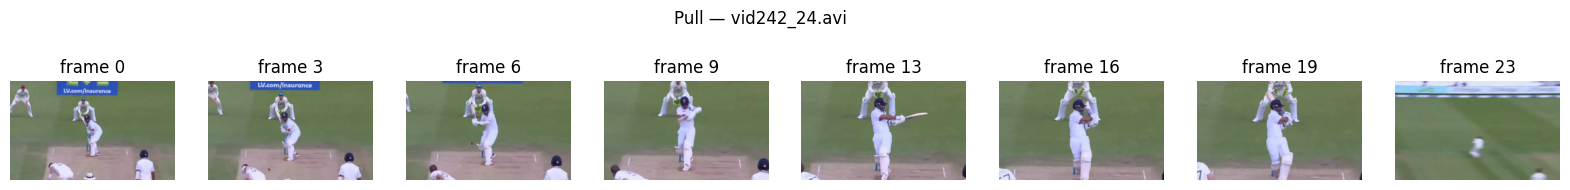

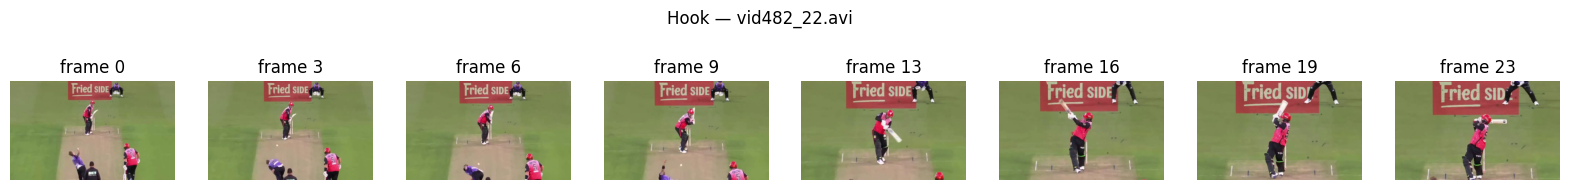

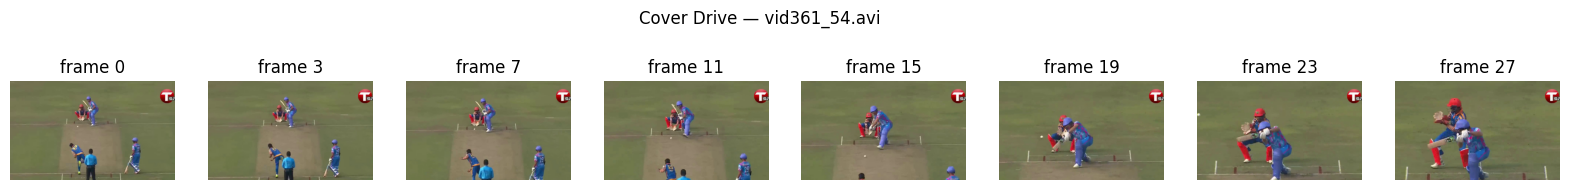

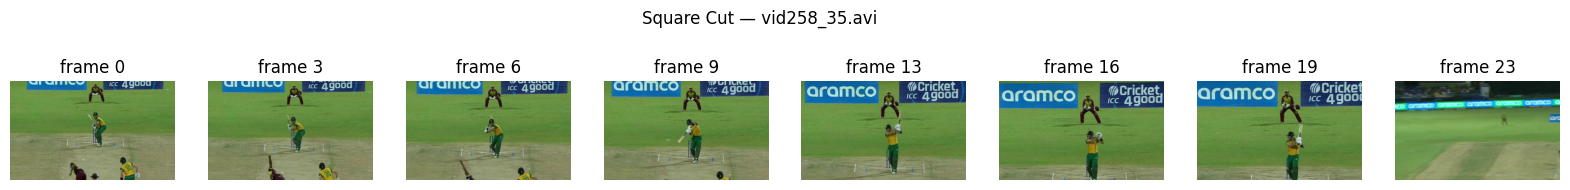

In [7]:
import cv2, random, numpy as np, matplotlib.pyplot as plt

def show_clip(path, n=8):
    cap = cv2.VideoCapture(path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    idxs = np.linspace(0, total - 1, n).astype(int)
    frames = []
    for i in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, i)
        ok, f = cap.read()
        if ok: frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
    cap.release()
    fig, axes = plt.subplots(1, len(frames), figsize=(2.5 * len(frames), 2.5))
    for ax, f, i in zip(axes, frames, idxs):
        ax.imshow(f); ax.set_title(f'frame {i}'); ax.axis('off')
    plt.suptitle(path.split('/')[-2] + ' — ' + path.split('/')[-1])
    plt.show()

for cls in ['Pull', 'Hook', 'Cover Drive', 'Square Cut']:
    clip = random.choice([v for v in videos if f'/{cls}/' in v])
    show_clip(clip)